##Combined Detector with new improved Frequency Branch
(RGB,Phase and removal of 2 augmentation methods)

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as transforms
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, random_split , Dataset
import timm
import numpy as np
from sklearn.metrics import accuracy_score, roc_auc_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt

torch.manual_seed(42)   #reproducibility
np.random.seed(42)

print("PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

PyTorch: 2.11.0+cu128
GPU: NVIDIA L4


## Set up and Data Loading

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import zipfile
import os
import shutil

with zipfile.ZipFile('/content/drive/MyDrive/data_combined_8k.zip', 'r') as z:
    for member in z.namelist():
        fixed_path = member.replace('\\', '/')
        target = os.path.join('/content', fixed_path)
        if member.endswith('\\') or '.' not in os.path.basename(fixed_path):
            os.makedirs(target, exist_ok=True)
        else:
            os.makedirs(os.path.dirname(target), exist_ok=True)
            with z.open(member) as src, open(target, 'wb') as dst:
                shutil.copyfileobj(src, dst)

print("Real frames:", len(os.listdir('/content/data_combined_8k/real')))
print("Fake frames:", len(os.listdir('/content/data_combined_8k/fake')))

Mounted at /content/drive
Real frames: 8000
Fake frames: 8000


## Frequency Branch (Refined Architecture)


In [ ]:
class FrequencyBranch(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(6, 16, kernel_size=3, padding=1),  #my 6 channels, RGB magnitude + RGB phase
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((4, 4))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 4 * 4, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3)
        )

    def forward(self, x):   # FFT now separately on R, G and B channels

        fft = torch.fft.fft2(x)
        fft = torch.fft.fftshift(fft, dim=(-2, -1))

        magnitude = torch.abs(fft)              # Magnitude for each RGB channel
        magnitude = torch.log1p(magnitude)

        magnitude = (
            magnitude -
            magnitude.mean(dim=(-2, -1), keepdim=True)
        ) / (
            magnitude.std(dim=(-2, -1), keepdim=True) + 1e-6
        )

        phase = torch.angle(fft)        # Phase for each RGB channel
        phase = phase / torch.pi

                                  # 3 magnitude + 3 phase = 6 input channels
        freq_input = torch.cat(
            [magnitude, phase],
            dim=1
        )

        out = self.features(freq_input)
        out = self.classifier(out)

        return out

In [ ]:
class CombinedDetector(nn.Module):
    def __init__(self):
        super().__init__()

        # stream 1= pretrained xceptionnet backbone
        self.xception = timm.create_model('xception', pretrained=True, num_classes=0)
        xception_features = self.xception.num_features  # 2048

        # stream 2= my custom frequency branch
        self.freq_branch = FrequencyBranch()
        freq_features = 128

        # fusion classifier combining both streams
        self.classifier = nn.Sequential(
            nn.Linear(xception_features + freq_features, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.5),
            nn.Linear(512, 128),
            nn.ReLU(inplace=True),
            nn.Dropout(0.3),
            nn.Linear(128, 2)
        )

    def forward(self, x_xception, x_freq):
        # spatial stream  receiving the fully augmented image
        spatial_features = self.xception(x_xception)

        # frequency stream  receives the less augmented image
        freq_features = self.freq_branch(x_freq)

        # combine both streams
        combined = torch.cat([spatial_features, freq_features], dim=1)

        # final classification
        out = self.classifier(combined)
        return out

# initialising my model
model = CombinedDetector().cuda()
print("Combined model loaded on GPU")
print(f"Trainable parameters: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

/usr/local/lib/python3.12/dist-packages/timm/models/_factory.py:138: UserWarning: Mapping deprecated model name xception to current legacy_xception.
  model = create_fn(


Downloading: "https://github.com/rwightman/pytorch-image-models/releases/download/v0.1-cadene/xception-43020ad28.pth" to /root/.cache/torch/hub/checkpoints/xception-43020ad28.pth
Combined model loaded on GPU
Trainable parameters: 22,142,938


## Dataset Split and Split-Stream Augmentation

streams receiving independently augmented copies of each training image

In [ ]:
full_dataset = ImageFolder('/content/data_combined_8k', transform=None)
print("Classes:", full_dataset.classes)
print("Total:", len(full_dataset))

train_size = int(0.7 * len(full_dataset))
val_size = int(0.15 * len(full_dataset))
test_size = len(full_dataset) - train_size - val_size

train_sub, val_sub, test_sub = random_split(full_dataset, [train_size, val_size, test_size])


xception_train_transform = transforms.Compose([    #full aug
    transforms.Resize((299, 299)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

freq_train_transform = transforms.Compose([    #less aug
    transforms.Resize((299, 299)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])

test_transform = transforms.Compose([   #none for val or test
    transforms.Resize((299, 299)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])



class DualTransformSubset(Dataset):
                                        #training--returns two independently-augmented copies of each image one per stream

    def __init__(self, subset, xception_transform, freq_transform):
        self.subset = subset
        self.xception_transform = xception_transform
        self.freq_transform = freq_transform
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        path, label = self.subset.dataset.samples[self.subset.indices[idx]]
        image = self.subset.dataset.loader(path)
        return self.xception_transform(image), self.freq_transform(image), label


class DualTestSubset(Dataset):
                                      #Val/test-- both streams receive the same unaugmented image

    def __init__(self, subset, transform):
        self.subset = subset
        self.transform = transform
    def __len__(self):
        return len(self.subset)
    def __getitem__(self, idx):
        path, label = self.subset.dataset.samples[self.subset.indices[idx]]
        image = self.subset.dataset.loader(path)
        img = self.transform(image)
        return img, img, label  # same image for both streams at eval time

train_set = DualTransformSubset(train_sub, xception_train_transform, freq_train_transform)
val_set = DualTestSubset(val_sub, test_transform)
test_set = DualTestSubset(test_sub, test_transform)

train_loader = DataLoader(train_set, batch_size=32, shuffle=True, num_workers=2)
val_loader = DataLoader(val_set, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_set, batch_size=32, shuffle=False, num_workers=2)

Classes: ['fake', 'real']
Total: 16000


##Training configuration
lower LR for the pretrained stream, higher LR for the randomly initialized frequency branch and classifier, with Adam optim, weight decay, and cosine annealing.

In [ ]:
num_epochs = 15

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam([
    {'params': model.xception.parameters(), 'lr': 0.00001},
    {'params': model.freq_branch.parameters(), 'lr': 0.0001},
    {'params': model.classifier.parameters(), 'lr': 0.0001}
], weight_decay=1e-4)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=num_epochs)

##Training and Validation Functions
Each batch contains separate spatial and frequency-domain inputs together with
the class labels.
During training, gradients are computed and the optimizer updates the model parameters.
During validation, gradient calculation is disabled and the model is evaluated using loss and classification accuracy


In [ ]:
def train_epoch(model, loader, optimizer, criterion):
    model.train()
    running_loss = 0
    correct = 0
    total = 0

    for x_xc, x_fr, labels in loader:
        x_xc, x_fr, labels = x_xc.cuda(), x_fr.cuda(), labels.cuda()
        optimizer.zero_grad()
        outputs = model(x_xc, x_fr)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
        _, predicted = outputs.max(1)
        correct += predicted.eq(labels).sum().item()
        total += labels.size(0)

    return running_loss/len(loader), 100.*correct/total

def val_epoch(model, loader, criterion):
    model.eval()
    running_loss = 0
    correct = 0
    total = 0

    with torch.no_grad():
        for x_xc, x_fr, labels in loader:
            x_xc, x_fr, labels = x_xc.cuda(), x_fr.cuda(), labels.cuda()
            outputs = model(x_xc, x_fr)
            loss = criterion(outputs, labels)

            running_loss += loss.item()
            _, predicted = outputs.max(1)
            correct += predicted.eq(labels).sum().item()
            total += labels.size(0)

    return running_loss/len(loader), 100.*correct/total

print("Training functions ready")

Training functions ready


##Training loop
Trains for 15 epochs, tracking loss and accuracy each epoch.The cosine-annealing scheduler is updated once per epoch. The
checkpoint with the highest validation accuracy is saved to Drive

In [ ]:

best_val_acc = 0
train_losses, val_losses = [], []
train_accs, val_accs = [], []

for epoch in range(num_epochs):
    train_loss, train_acc = train_epoch(model, train_loader, optimizer, criterion)
    val_loss, val_acc = val_epoch(model, val_loader, criterion)
    scheduler.step()

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}/{num_epochs} | "
          f"Train Loss: {train_loss:.4f} | Train Acc: {train_acc:.2f}% | "
          f"Val Loss: {val_loss:.4f} | Val Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), '/content/drive/MyDrive/best_model_combinedwimpfftsplitaug.pth')
        print(f"  -> Best model saved")

print(f"\nBest validation accuracy: {best_val_acc:.2f}%")

Epoch 1/15 | Train Loss: 0.6940 | Train Acc: 50.25% | Val Loss: 0.6879 | Val Acc: 58.62%
  -> Best model saved
Epoch 2/15 | Train Loss: 0.6098 | Train Acc: 66.35% | Val Loss: 0.4992 | Val Acc: 75.21%
  -> Best model saved
Epoch 3/15 | Train Loss: 0.4671 | Train Acc: 77.24% | Val Loss: 0.4315 | Val Acc: 78.83%
  -> Best model saved
Epoch 4/15 | Train Loss: 0.3917 | Train Acc: 81.69% | Val Loss: 0.3841 | Val Acc: 82.12%
  -> Best model saved
Epoch 5/15 | Train Loss: 0.3376 | Train Acc: 84.78% | Val Loss: 0.3542 | Val Acc: 84.25%
  -> Best model saved
Epoch 6/15 | Train Loss: 0.3016 | Train Acc: 86.33% | Val Loss: 0.3411 | Val Acc: 84.25%
Epoch 7/15 | Train Loss: 0.2702 | Train Acc: 88.16% | Val Loss: 0.3207 | Val Acc: 86.12%
  -> Best model saved
Epoch 8/15 | Train Loss: 0.2446 | Train Acc: 89.36% | Val Loss: 0.3128 | Val Acc: 85.83%
Epoch 9/15 | Train Loss: 0.2324 | Train Acc: 89.94% | Val Loss: 0.3002 | Val Acc: 87.62%
  -> Best model saved
Epoch 10/15 | Train Loss: 0.2146 | Train Acc:

##Test set evaluation

Evaluates model on held out test set, Predictions and class probabilities calculated, ( results: accuracy, AUC-ROC, F1 score and the confusion matrix)

In [ ]:

model.load_state_dict(
    torch.load('/content/drive/MyDrive/best_model_combinedwimpfftsplitaug.pth')
)

model.eval()
all_preds, all_labels, all_probs = [], [], []
with torch.no_grad():
    for x_xc, x_fr, labels in test_loader:
        x_xc, x_fr, labels = x_xc.cuda(), x_fr.cuda(), labels.cuda()
        outputs = model(x_xc, x_fr)
        probs = torch.softmax(outputs, dim=1)[:, 1]
        _, predicted = outputs.max(1)
        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
        all_probs.extend(probs.cpu().numpy())

acc = accuracy_score(all_labels, all_preds)
auc = roc_auc_score(all_labels, all_probs)
f1 = f1_score(all_labels, all_preds)
cm = confusion_matrix(all_labels, all_preds)
print(f"Test Accuracy: {acc*100:.2f}%")
print(f"AUC-ROC: {auc:.4f}")
print(f"F1 Score: {f1:.4f}")
print(f"Confusion Matrix:\n{cm}")

Test Accuracy: 87.12%
AUC-ROC: 0.9494
F1 Score: 0.8702
Confusion Matrix:
[[1055  150]
 [ 159 1036]]


##Training Curves
Plotting training/validation loss and accuracy across all 15 epochs. (later combined with Baseline's equivalent curves to
produce Fig. 2 in the final report)

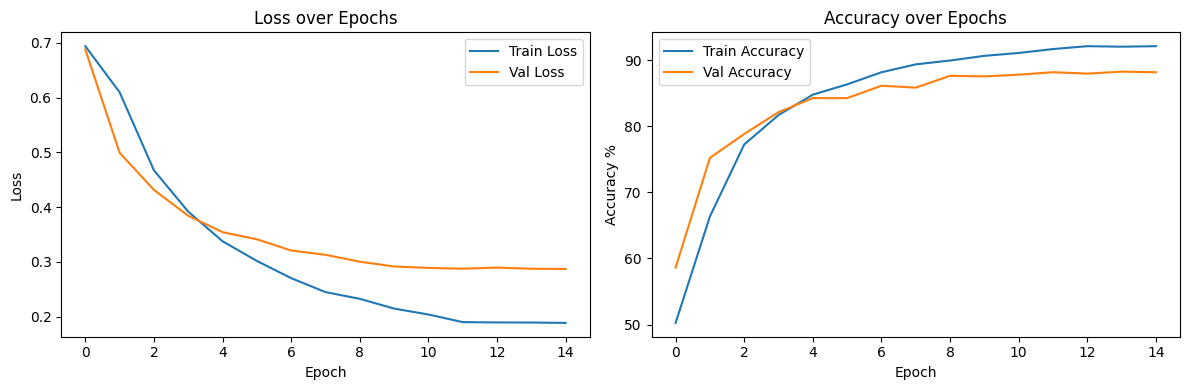

Saved to Google Drive


In [ ]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(train_losses, label='Train Loss')
ax1.plot(val_losses, label='Val Loss')
ax1.set_title('Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend()

ax2.plot(train_accs, label='Train Accuracy')
ax2.plot(val_accs, label='Val Accuracy')
ax2.set_title('Accuracy over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy %')
ax2.legend()

plt.tight_layout()
plt.savefig('/content/drive/MyDrive/training_curves_combinedwimpfftsplitaug.png', dpi=150)
plt.show()
print("Saved to Google Drive")


##Comparison curves
Compares the recorded training and validation loss and accuracy of the final CombinedDetector and XceptionNet baseline runs. The values were taken from their trainings and plotted together for direct comparison.

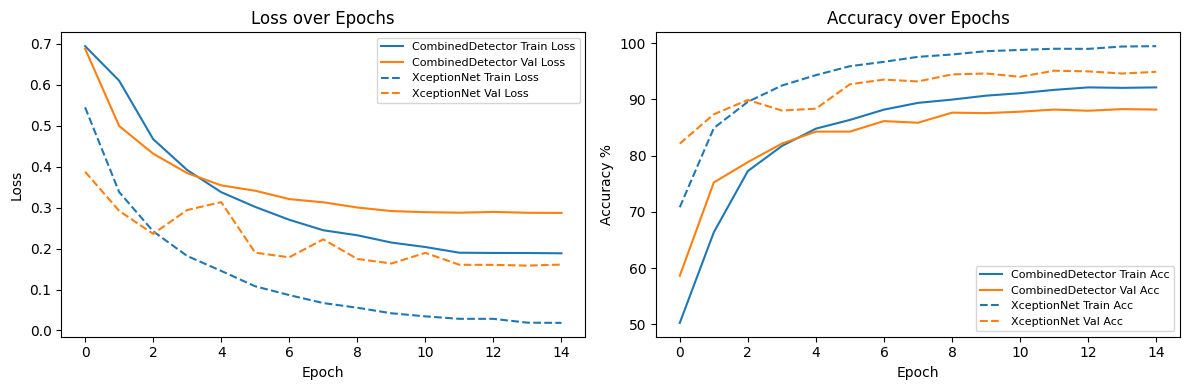

In [ ]:
import matplotlib.pyplot as plt


combined_train_losses = [0.6940, 0.6098, 0.4671, 0.3917, 0.3376, 0.3016, 0.2702, 0.2446, 0.2324, 0.2146, 0.2037, 0.1898, 0.1892, 0.1891, 0.1884]
combined_val_losses   = [0.6879, 0.4992, 0.4315, 0.3841, 0.3542, 0.3411, 0.3207, 0.3128, 0.3002, 0.2914, 0.2888, 0.2875, 0.2894, 0.2873, 0.2869]
combined_train_accs   = [50.25, 66.35, 77.24, 81.69, 84.78, 86.33, 88.16, 89.36, 89.94, 90.64, 91.08, 91.67, 92.11, 92.03, 92.11]
combined_val_accs     = [58.62, 75.21, 78.83, 82.12, 84.25, 84.25, 86.12, 85.83, 87.62, 87.54, 87.79, 88.17, 87.96, 88.25, 88.17]


xception_train_losses = [0.5447, 0.3379, 0.2421, 0.1818, 0.1454, 0.1078, 0.0863, 0.0669, 0.0555, 0.0420, 0.0344, 0.0284, 0.0284, 0.0190, 0.0185]
xception_val_losses   = [0.3874, 0.2920, 0.2358, 0.2940, 0.3133, 0.1898, 0.1786, 0.2224, 0.1746, 0.1635, 0.1894, 0.1604, 0.1601, 0.1583, 0.1608]
xception_train_accs   = [70.81, 84.88, 89.55, 92.44, 94.29, 95.88, 96.66, 97.54, 97.96, 98.55, 98.77, 98.98, 98.96, 99.38, 99.44]
xception_val_accs     = [82.12, 87.33, 89.88, 88.00, 88.33, 92.67, 93.50, 93.17, 94.42, 94.58, 94.00, 95.08, 94.96, 94.58, 94.88]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.plot(combined_train_losses, color='tab:blue', label='CombinedDetector Train Loss')
ax1.plot(combined_val_losses, color='tab:orange', label='CombinedDetector Val Loss')
ax1.plot(xception_train_losses, '--', color='tab:blue', label='XceptionNet Train Loss')
ax1.plot(xception_val_losses, '--', color='tab:orange', label='XceptionNet Val Loss')
ax1.set_title('Loss over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.legend(fontsize=8)

ax2.plot(combined_train_accs, color='tab:blue', label='CombinedDetector Train Acc')
ax2.plot(combined_val_accs, color='tab:orange', label='CombinedDetector Val Acc')
ax2.plot(xception_train_accs, '--', color='tab:blue', label='XceptionNet Train Acc')
ax2.plot(xception_val_accs, '--', color='tab:orange', label='XceptionNet Val Acc')
ax2.set_title('Accuracy over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy %')
ax2.legend(fontsize=8)

plt.tight_layout()
plt.savefig('/content/training_curves_both.png', dpi=150)
plt.show()